# IBM heavy-hex lattice: a 27-qubit Falcon (ibmq_montreal), a Quantcore-PDK rebuild, step by step

**What the chip is.** IBM's heavy-hexagon lattice (Chamberland et al., PRX 10, 011022 (2020)), used on every IBM
processor since 2021: fixed-frequency transmons on the vertices (degree 3) and on the edges (degree 2) of a hexagonal
lattice, each pair coupled by a resonant bus, cross-resonance gates. The 27-qubit Falcon cut (ibmq_montreal, Falcon r4)
is two long rows of ten qubits, three bridge qubits between them and four "spur" qubits that would bridge to the next
rows of a larger lattice.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica** (spec `docs/designs/ibm/ibm_falcon_27q.md`).
No layout of a heavy-hex chip is public; IBM's published device data set the graph and the targets, the layout is ours:
a **heavy-hex generator** (`heavy_hex(rows)`, before the Design — more or longer rows give Hummingbird- or Eagle-size lattices),
Quantum Metal's `TransmonPocket6` (IBM's pocket transmon, through `metal:`) with **Quantcore trilayer junctions** sized
per qubit by the PDK junction rule, one λ/2 meander bus per edge, a λ/4 readout per qubit on three feedlines
(airbridges where the middle feedline crosses the three bridge buses), Quantcore `BondPad`s, the PDK die frame (QCT),
sapphire 650 µm (εr 10.25), and the qcc LOM.

| | from the source | adapted here (why) |
|---|---|---|
| graph | ibmq_montreal coupling map (28 edges, IBM numbering 0–26); heavy-hex degree ≤ 3 (Chamberland) | generated by `heavy_hex([(1, 10), (0, 9)])` and mapped to IBM's numbering |
| f_q, α | Qiskit `FakeMontreal` Hamiltonian (2021-03-15): f_q 4.835–5.105 GHz, α −308 … −390 MHz | f_q matched per qubit with its junction (R_n 40–50 kΩ); α ≈ −150 MHz (R_n ≤ 50 kΩ caps L_J at 7.5 nH). LOM 4 tries the two alternatives (#49) |
| J | `jq` of the same Hamiltonian: 1.31–2.01 MHz | set by the bus coupling pads (one pad size for all edges) |
| buses | "fixed-frequency transmons via microwave-resonant buses" (Chamberland §II C); frequencies not published | λ/2 meanders, 6.2 / 6.5 GHz on alternating row edges, 6.35 GHz on vertical edges (assumed) |
| readout | measurement LO 7.19–7.46 GHz per qubit (same backend) | λ/4 hangers on three feedlines (top, middle, bottom); Falcon reads out through an interposer (bump-bonded) |
| drive | dedicated drive lines (interposer) | through the readout feedlines (not drawn: planar single die) |
| junctions | Al/AlOx (not given) | Quantcore Nb/AlOx/Nb trilayer junctions (PDK rule: Δ 1.4 meV, R_n 40–50 kΩ) |
| pads | (no layout) | **PDK pad rule**: six feedline pads, each etch `frame.pad_edge` = 100 µm from the die edge (`edge="auto"`) |
| placement | (no layout) | the lattice sits at the die centre (checked in Design 8) |
| cheese | (no layout to take it from) | **PDK band** (`cheese: "auto"`): no original cheese exists |

**Licences.** Device data from `qiskit-ibm-runtime` (Apache-2.0; local copy `build/external/qiskit_fake_backends/`)
and the cited paper; layout and code are ours (GPL, as the repository).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die sized to the lattice, the six feedline pads, the three feedlines (the middle one with
its airbridges), the 27 pocket transmons with their trilayer junctions, their 27 λ/4 hanger readouts, the 28 λ/2 buses
of the heavy-hex graph, and then the whole chip (the centring check, the targets and sim groups, the save). The
the two alternatives for α and the collisions (LOM 4) stay what-ifs on copies, after the save. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `ibm_falcon_27q.v1.ipynb`; both save the same
`ibm_falcon_27q.json`.

## Setup

The notebook runs from the repository root; `_common` holds the table, snapshot, coupling and PDK helpers. `LIVE`
follows `QCC_LIVE` (live KLayout, or headless snapshots with `QCC_LIVE=0`).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from collections import Counter
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, coupling and PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/ibm")

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on; the library applies each of them (frame and cheese in the build, the pad rule
through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings).

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## The heavy-hex graph

**The heavy-hex generator.** `heavy_hex(rows)` lays the graph out on a grid of columns and levels: long rows on even
levels, bridge qubits between them every fourth column (alternating offset), optional spur qubits above the top row
and below the bottom row. The Falcon cut is two long rows (columns 1–10 and 0–9), three bridges and four spurs; the
map to IBM's numbering is checked against the ibmq_montreal coupling map.

In [5]:
def heavy_hex(rows, offset=1, spurs=True):
    """Heavy-hex patch: ``rows`` = column ranges (c0, c1) of the long rows, bottom to top. Bridges join long rows r and
    r + 1 at columns c ≡ offset + 2r (mod 4); with ``spurs``, qubits also hang above the top row and below the bottom
    row where the next bridges would be (the Falcon cut has four). Returns ``sites`` {key: (column, level)} (level 2r:
    long rows, 2r + 1: bridges, −1 / 2R − 1: spurs) and ``edges`` [(key, key)]. Falcon 27:
    ``heavy_hex([(1, 10), (0, 9)])``; Eagle 127 (144 edges): ``heavy_hex([(0, 13)] + [(0, 14)] * 5 + [(1, 14)],
    offset=0, spurs=False)``."""
    sites, edges, n = {}, [], len(rows)
    for r, (c0, c1) in enumerate(rows):
        for c in range(c0, c1 + 1):
            sites[("L", r, c)] = (c, 2 * r)
            if c > c0:
                edges.append((("L", r, c - 1), ("L", r, c)))
    for r in range(n - 1):
        lo, hi = max(rows[r][0], rows[r + 1][0]), min(rows[r][1], rows[r + 1][1])
        for c in range(lo, hi + 1):
            if c % 4 == (offset + 2 * r) % 4:
                sites[("B", r, c)] = (c, 2 * r + 1)
                edges += [(("L", r, c), ("B", r, c)), (("B", r, c), ("L", r + 1, c))]
    ends = ((0, -1, (offset - 2) % 4), (n - 1, 2 * n - 1, (offset + 2 * (n - 1)) % 4)) if spurs else ()
    for r, level, off in ends:
        for c in range(rows[r][0], rows[r][1] + 1):
            if c % 4 == off:
                sites[("S", level, c)] = (c, level)
                edges.append((("S", level, c), ("L", r, c)) if level < 0 else (("L", r, c), ("S", level, c)))
    return sites, edges


SITES, EDGES = heavy_hex([(1, 10), (0, 9)])
IBM = {("L", 0, c): i for c, i in zip(range(1, 11), (3, 5, 8, 11, 14, 16, 19, 22, 25, 26))}
IBM |= {("L", 1, c): i for c, i in zip(range(0, 10), (0, 1, 4, 7, 10, 12, 15, 18, 21, 23))}
IBM |= {("B", 0, 1): 2, ("B", 0, 5): 13, ("B", 0, 9): 24, ("S", 3, 3): 6, ("S", 3, 7): 17, ("S", -1, 3): 9,
        ("S", -1, 7): 20}
NAME = {k: f"Q{IBM[k]}" for k in SITES}
COUPLING_MAP = [(0, 1), (1, 2), (1, 4), (2, 3), (3, 5), (4, 7), (5, 8), (6, 7), (7, 10), (8, 9), (8, 11), (10, 12),
                (11, 14), (12, 13), (12, 15), (13, 14), (14, 16), (15, 18), (16, 19), (17, 18), (18, 21), (19, 20),
                (19, 22), (21, 23), (22, 25), (23, 24), (24, 25), (25, 26)]
assert sorted(tuple(sorted((IBM[a], IBM[b]))) for a, b in EDGES) == COUPLING_MAP, "not the Falcon graph"
print(len(SITES), "qubits,", len(EDGES), "edges: the ibmq_montreal coupling map")

27 qubits, 28 edges: the ibmq_montreal coupling map


## The source targets

**Source targets**: ibmq_montreal (Qiskit `FakeMontreal`, Falcon r4, 2021-03-15; the Hamiltonian's variables ÷ 2π):
qubit frequencies, anharmonicities, readout LO centres and the exchange couplings `jq`.

In [6]:
F_Q = dict(enumerate([4.9107, 4.8347, 4.9824, 5.1049, 5.0037, 5.0331, 4.9506, 4.9057, 4.9082, 5.0446, 5.0819, 5.0341,
                      4.9723, 4.8683, 4.9609, 5.0339, 5.0855, 5.0721, 4.9814, 4.9832, 5.0822, 5.0733, 5.057, 4.9728,
                      5.0515, 4.9342, 4.9999]))                                         # GHz
ALPHA = dict(enumerate([-339.6, -324.5, -340.0, -335.3, -338.3, -337.4, -390.0, -323.2, -324.5, -338.1, -337.0,
                        -337.5, -322.0, -340.5, -323.2, -338.4, -337.3, -338.2, -326.2, -321.3, -337.7, -307.7,
                        -338.5, -337.3, -337.9, -322.9, -339.4]))                       # MHz
F_RO = dict(enumerate([7.2714, 7.3857, 7.2633, 7.3992, 7.3276, 7.3409, 7.4433, 7.1922, 7.1976, 7.4449, 7.2708,
                       7.3387, 7.4348, 7.3305, 7.3878, 7.3993, 7.2773, 7.4483, 7.1929, 7.2036, 7.4557, 7.3488,
                       7.3365, 7.4138, 7.2821, 7.3925, 7.282]))                        # GHz, meas LO centres
J_SRC = {(0, 1): 1.312, (1, 2): 1.399, (1, 4): 1.324, (2, 3): 1.36, (3, 5): 1.488, (4, 7): 1.441, (5, 8): 1.407,
         (6, 7): 2.014, (7, 10): 1.418, (8, 9): 1.416, (8, 11): 1.472, (10, 12): 1.583, (11, 14): 1.395,
         (12, 13): 1.359, (12, 15): 1.486, (13, 14): 1.36, (14, 16): 1.547, (15, 18): 1.695, (16, 19): 1.474,
         (17, 18): 1.525, (18, 21): 1.487, (19, 20): 1.461, (19, 22): 1.488, (21, 23): 1.418, (22, 25): 1.362,
         (23, 24): 1.305, (24, 25): 1.507, (25, 26): 1.433}                             # MHz

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedlines are drawn as soon as
their pads exist (segment 3), the readouts once the qubits are there (segment 5) and the buses after them (segment 6).
Every position comes from the graph (`xy(key)`, the pitches `PH`, `PV`) and `Y_FEED`, so the order changes nothing;
the middle feedline's airbridges are at the bridge qubits' columns, where their buses will cross.

| segment | what is placed here |
|---|---|
| 1 | the 27 × 15.2 mm die sized to the lattice, with its frame |
| 2 | six bond pads: one at each end of the three feedlines, west and east |
| 3 | the readout line: three straight feedlines (top, middle, bottom); the middle one with airbridges where the bridge buses will cross it |
| 4 | the 27 `TransmonPocket6` pockets on the heavy-hex sites, each with its trilayer junction and its bus / readout pads |
| 5 | the 27 λ/4 hanger readouts on their feedlines |
| 6 | the coupling: the 28 λ/2 meander buses, one per edge of the graph |
| 7 | the control routing: none (drive through the readout feedlines) |
| 8 | the whole chip: the centring check, the targets and sim groups, the save |

## Design 1 · The die and its frame

The die is sized to the lattice: 2.5 mm margins round ten 2.2 mm columns (27 × 15.2 mm). The build draws the PDK frame
(dicing L's, alignment grids, chip boundary, the device ID `HHX27` on a free edge).

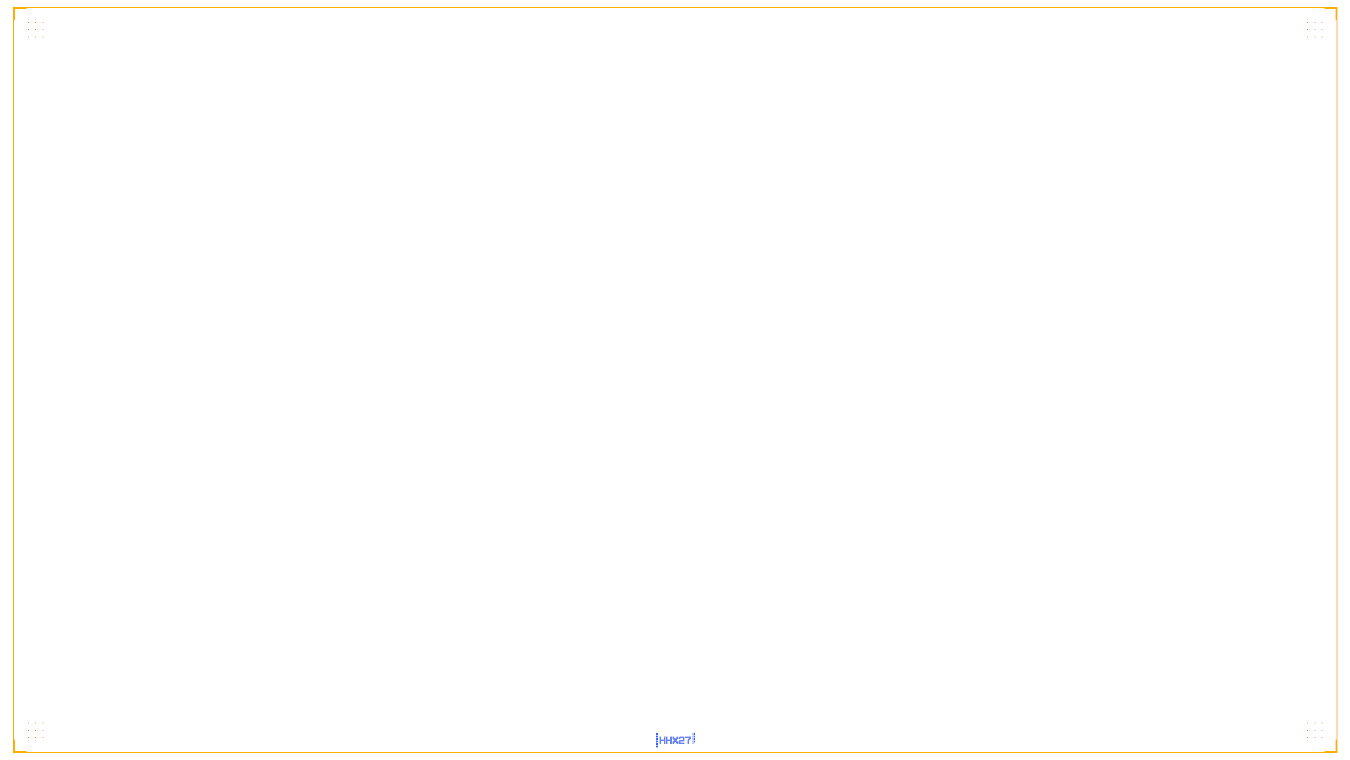

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/ibm/ibm_falcon_27q_die.png')

In [7]:
PH, PV = 2200, 2400                              # column pitch, level pitch
X0, Y0 = 2500, 5200                              # column 0, level 0 (the bottom long row)
W, H = X0 * 2 + 10 * PH, 15200
xy = lambda key: (X0 + SITES[key][0] * PH, Y0 + SITES[key][1] * PV)
d = Designer("ibm_falcon_27q", box=(0, 0, W, H), chip={"name_chip": "HHX27"}, live=LIVE)
layout_step(d, OUT / "ibm_falcon_27q_die.png", size=(1350, 760), width=640)

## Design 2 · Bond pads: the PDK pad rule

Three horizontal feedlines (above the top row, between the rows, below the bottom row), each between a pad on the west
and the east edge. The PDK puts each pad's outer etch edge **`frame.pad_edge` = 100 µm from the die edge**;
`edge="auto"` slides it perpendicular to its nearest edge until that holds, keeping its height.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| FL_top_in | `BondPad` | w | 100.0 | ✓ |
| FL_top_out | `BondPad` | e | 100.0 | ✓ |
| FL_mid_in | `BondPad` | w | 100.0 | ✓ |
| FL_mid_out | `BondPad` | e | 100.0 | ✓ |
| FL_bot_in | `BondPad` | w | 100.0 | ✓ |
| FL_bot_out | `BondPad` | e | 100.0 | ✓ |

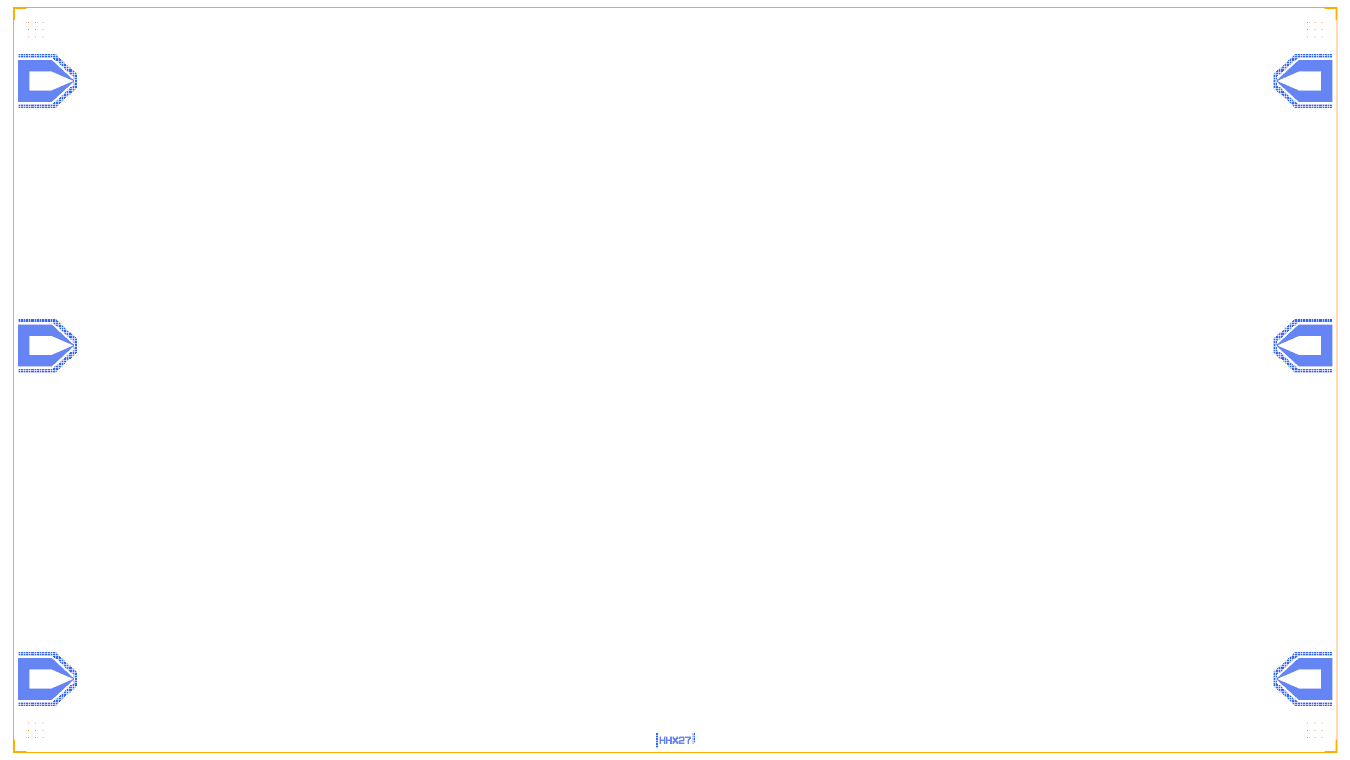

**On the chip so far:** 6 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 6 component(s) `FL_top_in`, `FL_top_out`, `FL_mid_in`, `FL_mid_out`, `FL_bot_in`, `FL_bot_out`.

WindowsPath('examples/designs/ibm/ibm_falcon_27q_s2_pads.png')

In [8]:
Y_FEED = {"top": Y0 + 3 * PV + 1300, "mid": Y0 + PV + 700, "bot": Y0 - PV - 1300}
fpad = {}
for side, y in Y_FEED.items():
    fpad[side] = (d.add(f"FL_{side}_in", "BondPad", at=(1150, y), rot=-90, edge="auto"),
                  d.add(f"FL_{side}_out", "BondPad", at=(W - 1150, y), rot=90, edge="auto"))
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "ibm_falcon_27q_s2_pads.png", size=(1350, 760), width=640)

## Design 3 · Readout: the three feedlines

- **Feedlines:** straight through-lines between their side pads; the middle one crosses the three bridge buses on
  **airbridges** (`d.waypoint(..., airbridge=True)`). They need no qubit, so they come
first; every readout will hang on one of them (Design 5). The airbridge waypoints sit at the bridge qubits' columns
(`xy(k)[0]`), where the vertical buses of Design 6 cross the middle line.

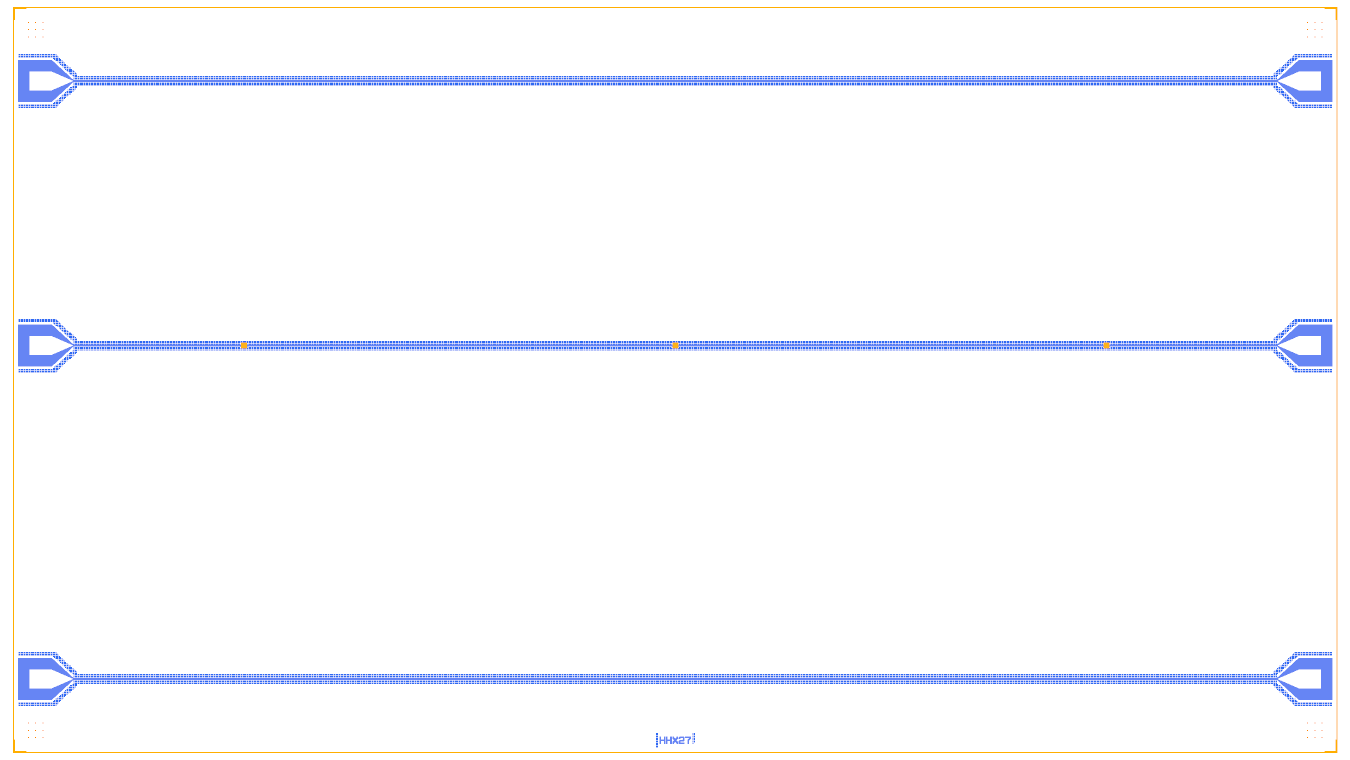

**On the chip so far:** 6 pads · 0 qubits · 0 other components · 3 routes · 0 declared couplings. **This step added** 3 route(s) `FL_top`, `FL_mid`, `FL_bot`.

WindowsPath('examples/designs/ibm/ibm_falcon_27q_s3_feedlines.png')

In [9]:
fl = {}
for side, y in Y_FEED.items():
    a, b = fpad[side]
    bridges = [d.waypoint((xy(k)[0], y), airbridge=True) for k in SITES if k[0] == "B"] if side == "mid" else None
    fl[side] = d.route(f"FL_{side}", a.a, b.a, nodes=bridges)
layout_step(d, OUT / "ibm_falcon_27q_s3_feedlines.png", size=(1350, 760), width=640)

## Design 4 · Qubit placement: 27 pockets with trilayer junctions

**Junctions.** One Quantcore trilayer junction per qubit, its L_J solved with the LOM (LOM 1 a) so that f_q lands on
IBM's frequency; all R_n fall in 43–48 kΩ, inside the PDK window.

In [10]:
LJ = {0: 7.172, 1: 7.096, 2: 6.814, 3: 6.492, 4: 6.797, 5: 6.674, 6: 7.034, 7: 6.883, 8: 6.891, 9: 6.782,
      10: 6.596, 11: 6.671, 12: 6.720, 13: 7.128, 14: 6.735, 15: 6.718, 16: 6.541, 17: 6.710, 18: 6.681,
      19: 6.691, 20: 6.684, 21: 6.617, 22: 6.613, 23: 6.840, 24: 6.634, 25: 6.806, 26: 6.900}  # nH (R_n 43–48 kΩ)
rn = {i: rn_from_lj(trilayer_junction("metal:TransmonPocket6", lj_nH=lj)[1]["Lj_nH"]) / 1e3 for i, lj in LJ.items()}
print(f"drawn R_n {min(rn.values()):.1f}–{max(rn.values()):.1f} kΩ")

drawn R_n 43.3–47.9 kΩ


**Connection pads.** Each pocket gets a bus pad towards each neighbour (corner pads ±x for row neighbours, middle pads
±y for vertical ones) and a readout pad: opposite its vertical bus, or away from the patch; a bridge qubit (buses both
up and down) reads out from a corner pad towards +x. `ro_side` records which feedline each readout uses.

Counter({2: 13, 3: 8, 1: 6}) qubits by degree


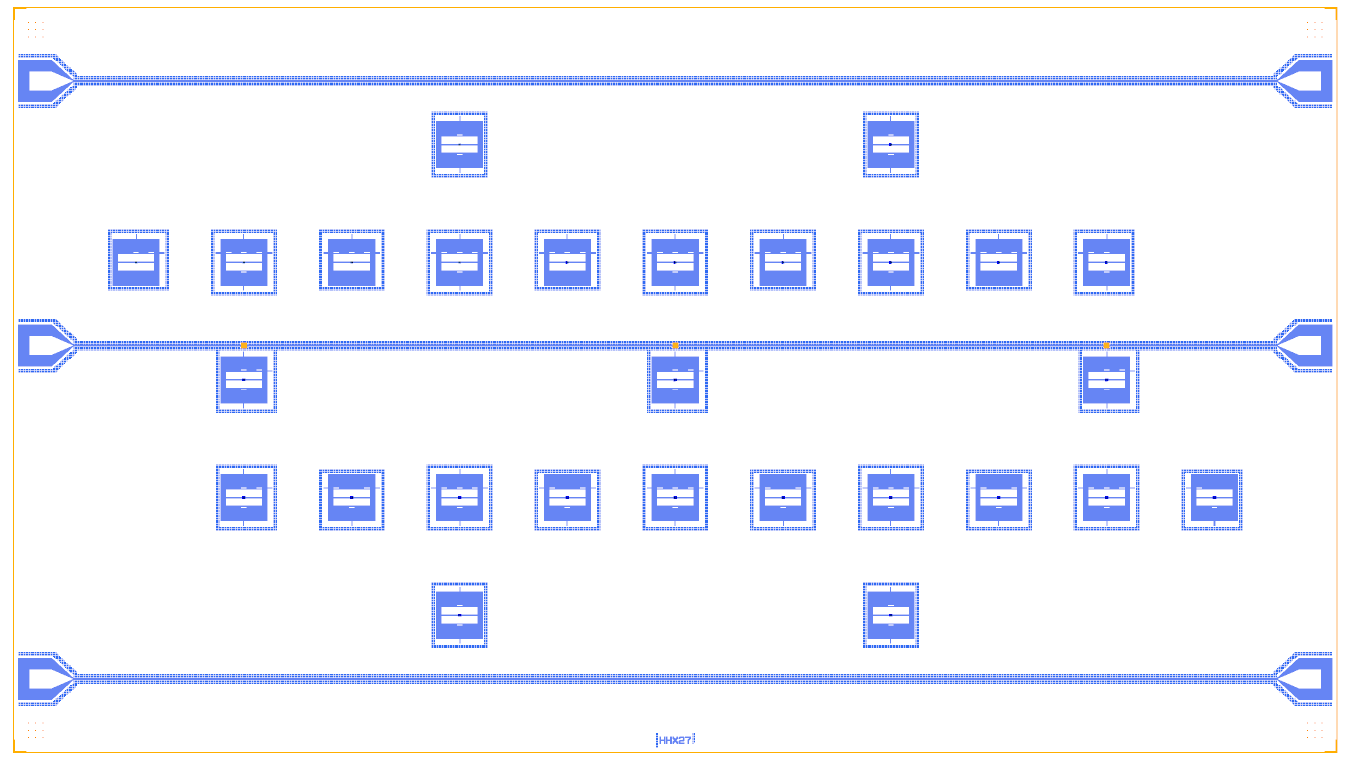

**On the chip so far:** 6 pads · 27 qubits · 0 other components · 3 routes · 0 declared couplings. **This step added** 27 component(s) `Q3`, `Q5`, `Q8`, `Q11`, `Q14`, `Q16`, `Q19`, `Q22` … (+19).

WindowsPath('examples/designs/ibm/ibm_falcon_27q_components.png')

In [11]:
POCKET = dict(pad_width=750, pad_height=160, pad_gap=20, pocket_width=950, pocket_height=950)
BUS_PAD, RO_PAD = 125, 120
nbr = {k: [] for k in SITES}
for a, b in EDGES:
    nbr[a].append(b)
    nbr[b].append(a)
pads, ro_side = {}, {}
top_row = max(lv for (_, lv) in SITES.values() if lv % 2 == 0)
for k, (c, lvl) in SITES.items():
    p = {}
    for o in nbr[k]:
        oc, ol = SITES[o]
        if ol == lvl:
            p["bw" if oc < c else "be"] = {"loc_W": -1 if oc < c else 1, "loc_H": 1, "pad_width": BUS_PAD}
        else:
            p["bn" if ol > lvl else "bs"] = {"loc_W": 0, "loc_H": 1 if ol > lvl else -1, "pad_width": BUS_PAD}
    if "bn" in p and "bs" in p:                   # a bridge: the readout leaves from a corner pad, towards +x, up
        p["ro"], up = {"loc_W": 1, "loc_H": 1, "pad_width": RO_PAD}, True
    else:                                         # opposite its vertical bus; without one, away from the patch
        up = "bs" in p if ("bn" in p or "bs" in p) else lvl >= top_row
        p["ro"] = {"loc_W": 0, "loc_H": 1 if up else -1, "pad_width": RO_PAD}
    y = Y0 + lvl * PV                             # the nearest feedline in the readout's direction
    ro_side[k] = min((f for f, yf in Y_FEED.items() if (yf > y) == up), key=lambda f: abs(Y_FEED[f] - y))
    pads[k] = p
q = {}
for k in SITES:
    i = IBM[k]
    params, junction = trilayer_junction("metal:TransmonPocket6", lj_nH=LJ[i])
    q[k] = d.add(NAME[k], "metal:TransmonPocket6", at=xy(k), junction=junction, connection_pads=pads[k],
                 **POCKET, **params)
print(Counter(len(nbr[k]) for k in SITES), "qubits by degree")
layout_step(d, OUT / "ibm_falcon_27q_components.png", size=(1350, 760), width=640)

## Design 5 · Readout: 27 λ/4 hangers

- **Readouts:** λ/4 from the readout pad into a 300 µm **hanger** on the chosen feedline, shorted at its end; the
  lengths are set for IBM's readout frequencies with the LOM. `fl.hanger(near=(x, y))` centres the coupler at the
  feedline point nearest (x, y), here 150 µm to the right of where the readout reaches the line: given by position, not by
  arclength from the pad, the coupler stays at its qubit when the pads (and so the feedline's start) move. A bridge qubit's readout first runs +x
from its corner pad (one waypoint); the router adds one KQC `Meander` for whatever each length leaves over its path.

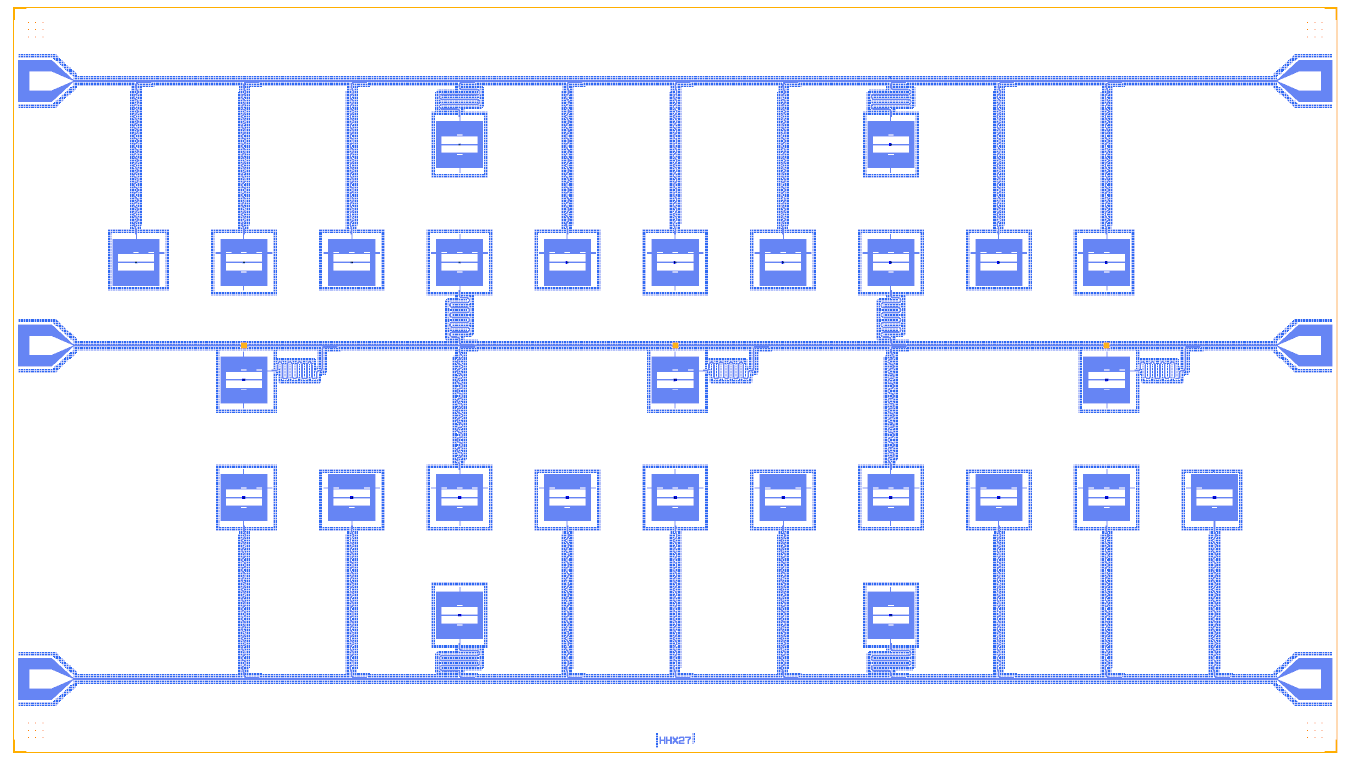

**On the chip so far:** 6 pads · 27 qubits · 0 other components · 30 routes · 0 declared couplings. **This step added** 27 route(s) `R3`, `R5`, `R8`, `R11`, `R14`, `R16`, `R19`, `R22` … (+19).

WindowsPath('examples/designs/ibm/ibm_falcon_27q_s5_readouts.png')

In [12]:
K_LEN = 300                                      # readout hanger coupling length
L_RO = {0: 4088, 1: 4020, 2: 4093, 3: 4013, 4: 4054, 5: 4047, 6: 3988, 7: 4137, 8: 4132, 9: 3987, 10: 4088,
        11: 4049, 12: 3991, 13: 4053, 14: 4020, 15: 4012, 16: 4085, 17: 3985, 18: 4136, 19: 4129, 20: 3981,
        21: 4042, 22: 4050, 23: 4004, 24: 4082, 25: 4017, 26: 4083}                 # λ/4 readouts (µm), for F_RO
for k in SITES:
    i, (x, y) = IBM[k], xy(k)
    yf = Y_FEED[ro_side[k]]
    x_start = x + 1600 if k[0] == "B" else x                 # a bridge's readout runs +x from its corner pad
    side = "left" if yf < y else "right"                     # the feedline travels +x: left = above it
    hang = fl[ro_side[k]].hanger(near=(x_start + K_LEN / 2, yf), length=K_LEN, side=side, ground_gap=4,
                                 end="short")
    nodes = [(x_start, y + 190)] if k[0] == "B" else None
    d.route(f"R{i}", q[k].ro, hang, meander=L_RO[i], r=50, nodes=nodes)
layout_step(d, OUT / "ibm_falcon_27q_s5_readouts.png", size=(1350, 760), width=640)

## Design 6 · Coupling: 28 λ/2 buses

- **Buses:** one λ/2 meander per edge, `L ≈ 60400 µm·GHz / f_bus` (the pad loading calibrated with the LOM) for an
  assumed plan: 6.2 / 6.5 GHz on alternating row edges, 6.35 GHz on vertical edges. A vertical bus leaves the lower
  qubit straight for 275 µm (the middle feedline crosses the bridge buses there). Each is a meander between its two bus pads;
the router adds one KQC `Meander` for the length the path leaves over.

{'R3': 4013, 'R5': 4047, 'R8': 4132, 'R11': 4049, 'R14': 4020, 'R16': 4085, 'R19': 4129, 'R22': 4050, 'R25': 4017, 'R26': 4083, 'R0': 4088, 'R1': 4020, 'R4': 4054, 'R7': 4137, 'R10': 4088, 'R12': 3991, 'R15': 4012, 'R18': 4136, 'R21': 4042, 'R23': 4004, 'R2': 4093, 'R13': 4053, 'R24': 4082, 'R9': 3987, 'R20': 3981, 'R6': 3988, 'R17': 3985, 'B_3_5': 9292, 'B_5_8': 9742, 'B_8_11': 9292, 'B_11_14': 9742, 'B_14_16': 9292, 'B_16_19': 9742, 'B_19_22': 9292, 'B_22_25': 9742, 'B_25_26': 9292, 'B_0_1': 9742, 'B_1_4': 9292, 'B_4_7': 9742, 'B_7_10': 9292, 'B_10_12': 9742, 'B_12_15': 9292, 'B_15_18': 9742, 'B_18_21': 9292, 'B_21_23': 9742, 'B_3_2': 9512, 'B_2_1': 9512, 'B_14_13': 9512, 'B_13_12': 9512, 'B_25_24': 9512, 'B_24_23': 9512, 'B_9_8': 9512, 'B_20_19': 9512, 'B_7_6': 9512, 'B_18_17': 9512}


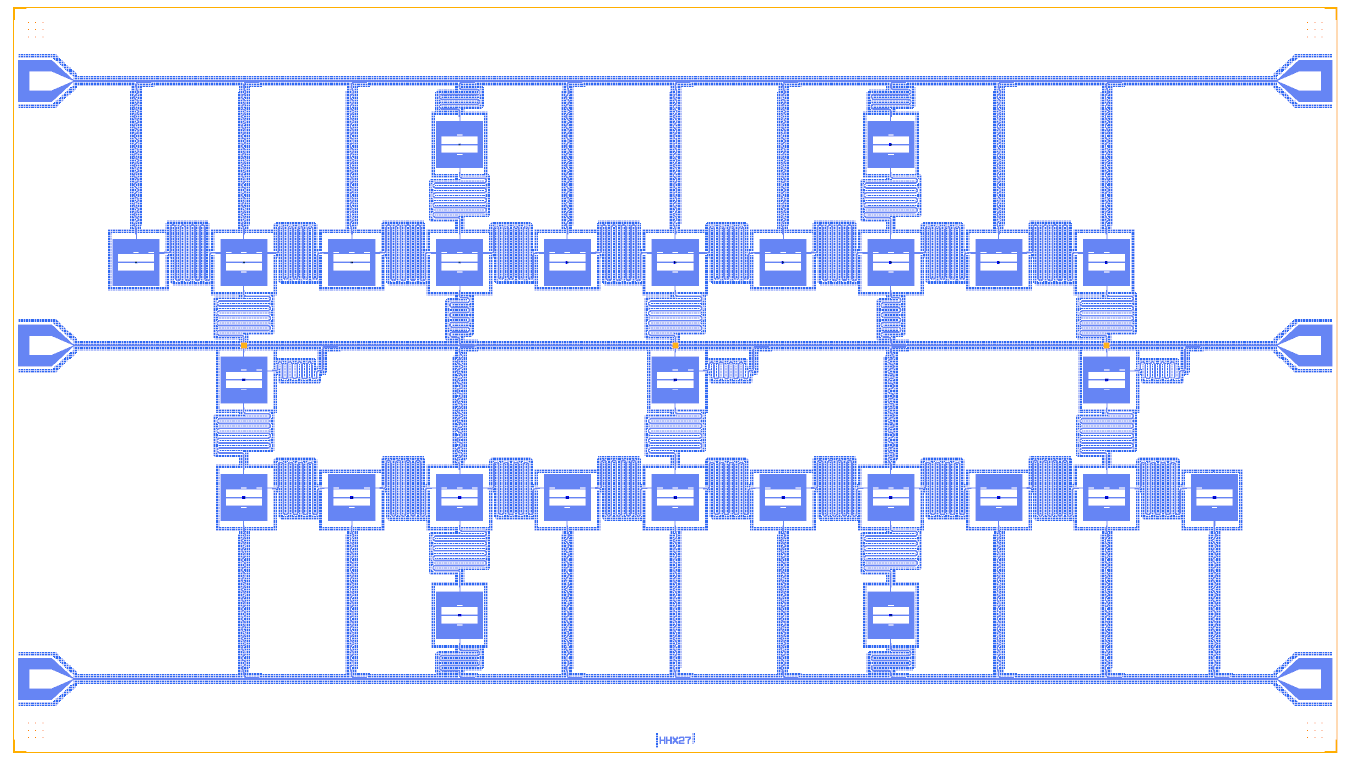

**On the chip so far:** 6 pads · 27 qubits · 0 other components · 58 routes · 0 declared couplings. **This step added** 28 route(s) `B_3_5`, `B_5_8`, `B_8_11`, `B_11_14`, `B_14_16`, `B_16_19`, `B_19_22`, `B_22_25` … (+20).

WindowsPath('examples/designs/ibm/ibm_falcon_27q_s6_buses.png')

In [13]:
def bus_f(a, b):
    """Assumed bus frequency plan (GHz): alternating 6.2 / 6.5 along the long rows, 6.35 on vertical edges."""
    (ca, la), (cb, lb) = SITES[a], SITES[b]
    return (6.2 if min(ca, cb) % 2 == 0 else 6.5) if la == lb else 6.35


L_BUS = {}                                       # λ/2 bus lengths per edge
for a, b in EDGES:
    (ca, la), (cb, lb) = SITES[a], SITES[b]
    if la == lb:
        lo, hi = (a, b) if ca < cb else (b, a)
        pa, pb, nodes = q[lo].be, q[hi].bw, None
    else:
        lo, hi = (a, b) if la < lb else (b, a)
        x, y = xy(lo)
        pa, pb, nodes = q[lo].bn, q[hi].bs, [(x, y + 850)]
    name = f"B_{IBM[lo]}_{IBM[hi]}"
    L_BUS.setdefault(name, round(60400 / bus_f(a, b)))      # ≈ λ/2 with the pad loading (calibrated, LOM 1)
    d.route(name, pa, pb, meander=L_BUS[name], r=50, nodes=nodes)
rebuild(d)
print({k: round(v) for k, v in d.result.route_lengths().items() if not k.startswith("FL")})
layout_step(d, OUT / "ibm_falcon_27q_s6_buses.png", size=(1350, 760), width=640)

## Design 7 · Routing: control lines

None: Falcon drives its qubits through dedicated lines on an interposer (bump-bonded); this planar single die drives
them through the readout feedlines instead, so no drive or flux line is drawn. Nothing is routed here.

## Design 8 · The whole chip: centring check, targets, sim groups, save

`center_in_die(d)` measures the bounding box of all instances and routes and shifts them to centre it; the die was
sized round the lattice, so it returns (0, 0).

Targets: IBM's f_q and α per qubit and its readout frequency. FEM boxes: a vertex qubit (Q12) with its three buses and
neighbours (C-matrix), and Q0 with its readout (C-matrix and eigenmode).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (the feedlines were added before the qubits and the readouts before the buses here), so `git diff` stays empty.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/ibm/ibm_falcon_27q.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer ibm_falcon_27q: 33 instances, 58 routes, live=False> → examples\designs\ibm\ibm_falcon_27q.json


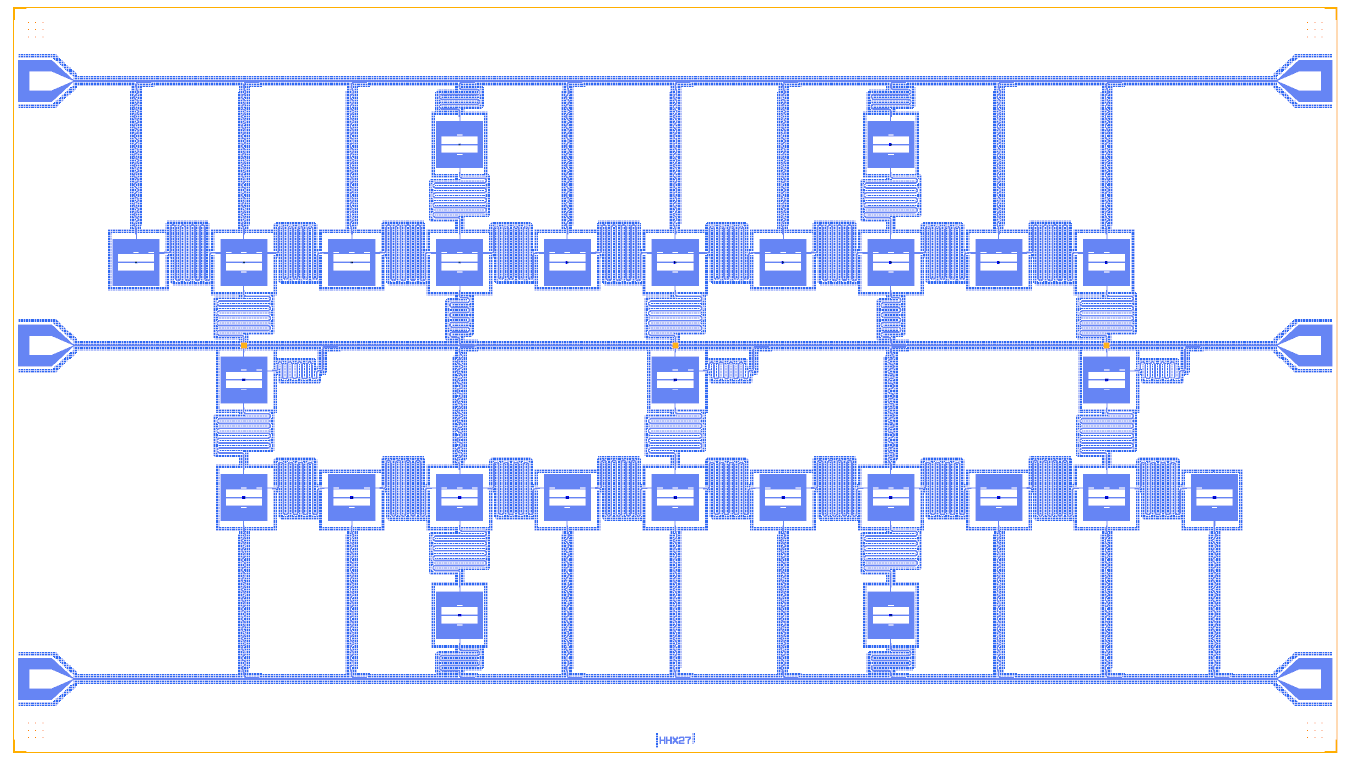

**On the chip so far:** 6 pads · 27 qubits · 0 other components · 58 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/ibm/ibm_falcon_27q_s8_chip.png')

In [14]:
print("centring shift (µm):", center_in_die(d))
d.targets(**{f"Q{i}": {"f_q_GHz": F_Q[i], "alpha_MHz": ALPHA[i]} for i in F_Q},
          **{f"R{i}": {"f_GHz": F_RO[i]} for i in F_RO})
d.sim_group("vertex_Q12", ["Q10", "Q12", "Q13", "Q15", "B_10_12", "B_13_12", "B_12_15"], margin_um=100,
            analyses=["q3d_cmatrix"])
d.sim_group("Q0_read", ["Q0", "R0"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
DESIGN, same = save_design(d, OUT / "ibm_falcon_27q.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "ibm_falcon_27q_s8_chip.png", size=(1350, 760), width=640)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

- **errors:** none expected;
- **warnings:** `dangling_port` on the `squid_a` / `squid_b` junction attachment points of the 27 pockets (the cell
  draws the trilayer junction across the pad gap itself);
- **PDK design warnings:** none expected (R_n in the window, f_q targets in 4–8 GHz, pads at 100 µm).

From the v1 run: **0 errors · 54 warnings (`dangling_port`) · 0 PDK design warnings**.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

27 floating pocket transmons (two pad nodes each, the drawn trilayer L_J / C_J), a node per connection pad; each edge's
meander is a λ/2 `TLres` joining the two bus pads; each readout a λ/4 `TLres` with a hanger κ into its feedline
(`FL_top`, `FL_mid`, `FL_bot`; the airbridges keep the middle one one conductor). The table lists the counts and the
first rows only.

In [ ]:
lb = d.lom()
md = netlist_md(lb)
display(Markdown("\n".join(md.splitlines()[:30]) + "\n\n…"))
print(Counter(b.type for b in lb.model.branches.values()), "| unconnected ports:", lb.unconnected)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

**(a) Qubit + readout pairs** (QuTiP dressed; IBM's values in brackets). L_J of Design 4 and the readout lengths were
solved with these groups.

From the v1 run: f_q 4.826–5.101 GHz, within 30 MHz of IBM's; α −143 … −151 MHz (IBM −308 … −390, LOM 4); f_r
7.082–7.340 GHz, 1.5 % (≈ 110 MHz) below IBM's measurement LOs: the lengths were set before the Nb film's kinetic
inductance (PDK `kinetic`) entered the LOM, which makes every line ≈ 1.5 % slower (flagged, not retuned); κ
0.31–0.34 MHz; χ −0.35 … −0.62 MHz.

In [ ]:
read = {f"Q{i}+R{i}": [f"Q{i}", f"R{i}", f"FL_{ro_side[k]}"] for k, i in sorted(IBM.items(), key=lambda t: t[1])}
results = simulate_groups(d, read)
display(Markdown(groups_md(results, d.data["targets"])))

**(b) Exchange coupling and ZZ on every edge** (qubit – bus – qubit, `exchange_coupling`: half the splitting at the
avoided crossing when the second qubit's L_J is swept through the first's frequency; ZZ at the design frequencies),
next to IBM's `jq`. About 15 s per edge, ≈ 7 min in all.

**Frequency collisions.** IBM's frequency pattern was laid out for α ≈ −330 MHz; with the PDK's α ≈ −145 MHz some of
its neighbour detunings (≈ 0.1–0.2 GHz) fall near |Δ| ≈ |α|, where |11⟩ meets |20⟩ / |02⟩ and the static ZZ grows to
hundreds of kHz or MHz (look for the large |ZZ| rows: Q8–Q9, Q1–Q2, Q2–Q3, Q22–Q25, Q24–Q25, Q7–Q10). LOM 4 tries
the two ways out.

From the v1 run: J 0.90–1.64 MHz (IBM 1.30–2.01); ZZ on the six colliding edges Q8–Q9 2.02 MHz, Q1–Q2 −1.81 MHz, Q2–Q3
1.08 MHz, Q22–Q25 476 kHz, Q24–Q25 336 kHz and Q7–Q10 −261 kHz; on the other 22 edges −25 … +126 kHz.

In [ ]:
BUS = {}
for a, b in EDGES:
    lo, hi = sorted((IBM[a], IBM[b]))
    BUS[(lo, hi)] = next(n for n in d.data["routes"] if n in (f"B_{lo}_{hi}", f"B_{hi}_{lo}"))
J = {}
for (lo, hi), bus in BUS.items():
    J[f"Q{lo}-Q{hi}"] = exchange_coupling(d, [f"Q{lo}", bus, f"Q{hi}"], f"Q{lo}", f"Q{hi}", n=4)
    J[f"Q{lo}-Q{hi}"]["bus"] = bus
display(Markdown(exchange_md(J, {f"Q{a}-Q{b}": v for (a, b), v in J_SRC.items()})))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes of the 27 qubit + readout pairs (QuCat; circles are qubits,
squares readouts; filled markers are the QuTiP dressed values; red bars the targets), (b) the dispersive shift |χ| of
each readout. From the v1 run the qubits sit on their red bars and every readout ≈ 1.5 % below its own (the Nb
kinetic inductance, LOM 1 a). The exchange couplings and ZZ of LOM 1 b are in their table.

In [ ]:
plot_lom(results, OUT / "ibm_falcon_27q_lom.png", targets=d.data["targets"], title="ibm_falcon_27q: LOM per qubit + readout")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. A readout is tuned by its length: R0 is shortened by 100 µm (≈ 2.5 %), so f_r rises by about as much and the qubit's
dispersive shift changes with the larger detuning. From the v1 run: f_r 7.160 → 7.327 GHz (+2.3 %), χ −0.422 →
−0.391 MHz; f_q stays at 4.929 GHz. `design_copy` opens a second, non-live Designer on the saved design;
the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["R0"].set(meander=L_RO[0] - 100)
res2 = simulate_groups(d2, {"Q0+R0": read["Q0+R0"]})
display(Markdown(params_delta_md({"Q0+R0": results["Q0+R0"]}, res2)))

## LOM 4 · the two alternatives for α and the collisions

With PDK junctions (R_n 40–50 kΩ, so L_J ≤ 7.5 nH and E_J/h ≥ 22 GHz), a 5 GHz pocket needs a large C_Σ and its α is
only ≈ −145 MHz against IBM's −330 MHz, so six of IBM's edges collide (|Δ| ≈ |α|). Both alternatives are shown. Both are LOM what-ifs on a copy of the design (the saved design is unchanged), on the ten
qubits of the six colliding edges only, so the section runs in a few minutes: each qubit with its readout, then each
edge (qubit – bus – qubit) once for f_q, α and the static ZZ.

A transmon has f_q ≈ √(8 E_J E_C) − E_C and α ≈ −E_C (a little more), with E_C/h = e²/2hC_Σ and
E_J/h = 163.46 GHz·nH / L_J. `resize` infers E_C from a simulated (L_J, f_q) and sets the L_J that puts f_q on the
target; two passes absorb the junction's own C_J.

In [ ]:
COLL = [(8, 9), (1, 2), (2, 3), (22, 25), (24, 25), (7, 10)]
QS = sorted({i for e in COLL for i in e})
EDGE_SEL = {f"Q{a}-Q{b}": [f"Q{a}", BUS[(a, b)], f"Q{b}"] for a, b in COLL}
GROUPS = {f"Q{i}": read[f"Q{i}+R{i}"] for i in QS}
F_T = {f"Q{i}": F_Q[i] for i in QS}
EJ_LJ = 163.46                                   # E_J/h (GHz) × L_J (nH) = (Φ0/2π)²/h


def ec_from(f_GHz, lj_nH):
    """E_C/h (GHz) of a transmon from its f_q and L_J: the small root of f = √(8 E_J E_C) − E_C."""
    s = math.sqrt(8 * EJ_LJ / lj_nH)
    return ((s - math.sqrt(s * s - 4 * f_GHz)) / 2) ** 2


def resize(dd, f_target, groups, cell="metal:TransmonPocket6", passes=2):
    """LOM what-if: re-draw each qubit's trilayer junction in ``dd`` for ``f_target`` (GHz)."""
    for _ in range(passes):
        res = simulate_groups(dd, {q_: groups[q_] for q_ in f_target})
        for q_, ft in f_target.items():
            ec = ec_from(res[q_].params[f"{q_}.f_q_GHz"], dd.data["instances"][q_]["junction"]["Lj_nH"])
            params, jj = trilayer_junction(cell, lj_nH=EJ_LJ * 8 * ec / (ft + ec) ** 2)
            dd[q_].set(junction=jj, **params)
    return simulate_groups(dd, {q_: groups[q_] for q_ in f_target})


def plan_md(dd, res, window):
    """Junction, f_q and α per qubit against IBM's, with the R_n window flag."""
    rows = [f"| qubit | L_J (nH) | R_n (kΩ) | R_n in {window[0]}–{window[1]} kΩ | f_q (GHz) [IBM] | α (MHz) [IBM] |",
            "|---|---|---|---|---|---|"]
    for q_, r in res.items():
        i = int(q_[1:])
        lj = dd.data["instances"][q_]["junction"]["Lj_nH"]
        rn_ = rn_from_lj(lj) / 1e3
        rows.append(f"| {q_} | {lj:.2f} | {rn_:.1f} | {'yes' if window[0] <= rn_ <= window[1] else 'no'} | "
                    f"{r.params[f'{q_}.f_q_GHz']:.4f} [{F_Q[i]}] | {r.params[f'{q_}.alpha_MHz']:.0f} [{ALPHA[i]}] |")
    return "\n".join(rows)


def collisions_md(dd):
    """Each colliding edge simulated once (qubit – bus – qubit): f_q, detuning, α and the static ZZ (QuTiP)."""
    res = simulate_groups(dd, EDGE_SEL, max_modes=3)
    fmt = lambda v, nd: "–" if v is None else f"{v:.{nd}f}"
    rows = ["| edge | f_a (GHz) | f_b (GHz) | Δ (MHz) | α_a / α_b (MHz) | ZZ (kHz) |", "|---|---|---|---|---|---|"]
    for g, r in res.items():
        a, b = g.split("-")
        p = r.params
        fa, fb = p.get(f"{a}.f_q_GHz"), p.get(f"{b}.f_q_GHz")
        z = next((z for z in r.dressed.get("zz", []) if set(z["pair"].split("-")) == {a, b}), None)
        zz = "hybridised" if z is None or z["hybridised"] else f"{z['zz_MHz'] * 1e3:.4g}"
        dlt = "–" if fa is None or fb is None else f"{(fb - fa) * 1e3:+.0f}"
        rows.append(f"| {g} | {fmt(fa, 4)} | {fmt(fb, 4)} | {dlt} | {fmt(p.get(f'{a}.alpha_MHz'), 0)} / "
                    f"{fmt(p.get(f'{b}.alpha_MHz'), 0)} | {zz} |")
    return "\n".join(rows)


display(Markdown("**The design (PDK window, C_Σ ≈ 140 fF), the six colliding edges:**\n\n" + collisions_md(d)))

**(A) A wider R_n window, 30–80 kΩ.** A larger L_J (up to 12 nH at 80 kΩ) lets a smaller pocket reach 5 GHz, and a
smaller pocket has the larger E_C IBM uses. The ten pockets' pads shrink from 750 × 160 to 380 × 100 µm (C_Σ ≈ 77 fF,
E_C ≈ 0.25 GHz) and their junctions are re-sized for IBM's f_q. From the v1 run: L_J 12.5–13.5 nH, R_n 83–90 kΩ: on
the PDK finger grid the drawn junctions land just above even the wider window (the table's "no"); α −314 … −349 MHz,
at IBM's; f_q within 1.2 % of IBM's. The detunings (73–208 MHz) now sit well inside |α| and the six edges stop
colliding: their ZZ drops to 26–157 kHz.

In [ ]:
dA = design_copy(DESIGN, "_wide_rn")
for i in QS:
    dA[f"Q{i}"].set(pad_width=380, pad_height=100)
resA = resize(dA, F_T, GROUPS)
display(Markdown(plan_md(dA, resA, (30, 80))))
display(Markdown(collisions_md(dA)))

**(B) A larger C_Σ inside the PDK window.** The ten pockets grow (pads 1000 × 200 µm in a 1250 × 1150 µm pocket,
C_Σ ≈ 190 fF) with the design's junctions (R_n 43–48 kΩ, in the window). A larger C_Σ lowers E_C: f_q falls to
4.20–4.43 GHz and α to −107 … −110 MHz (from the v1 run), so the collision band |Δ| ≈ |α| moves to smaller detunings (the detunings shrink
with f_q too). It does not bring back IBM's α: with detunings of 108–125 MHz, about |α|, the six edges' ZZ is −123 … +285 kHz
(Q8–Q9 285 kHz).

In [ ]:
dB = design_copy(DESIGN, "_big_c")
for i in QS:
    dB[f"Q{i}"].set(pad_width=1000, pad_height=200, pocket_width=1250, pocket_height=1150)
resB = simulate_groups(dB, GROUPS)
display(Markdown(plan_md(dB, resB, (40, 50))))
display(Markdown(collisions_md(dB)))

**Reading the two.** (A) brings α near IBM's and clears the collisions of IBM's frequency plan, at the price of
junctions outside today's PDK window (R_n 83–90 kΩ, smaller fingers). (B) stays in the window but lowers every
qubit and |α| further; a Quantcore heavy-hex chip with the PDK junctions needs its own frequency allocation
(Chamberland §II C redone for α ≈ −145 MHz). Neither is applied to the saved design: the rebuild keeps the PDK
junctions and flags the collisions.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/ibm/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Three jobs: a Q3D C-matrix job for the vertex qubit Q12 with its three buses and neighbours, and for Q0 a C-matrix
and an eigenmode job with its readout. Simulation exports never carry cheese; airbridges are left out unless
`build_simulation(..., airbridges=True)`. Exporting again replaces a job folder, results included.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/ibm/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["vertex_Q12", "Q0_read"])
jobs_eig = export_sims(DESIGN, ["Q0_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

Two C-matrices: the vertex qubit Q12 with its three buses and neighbours (`vertex_Q12`: the pads' C_g on a degree-3
site) and `Q0_read` (Q0 with its readout). Each net is named after its LOM node (each pocket's `island1` / `island2`,
the bus and readout pads), so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each job with
`RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

`Q0_read` in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet across the pad gap, the lines the box cuts end
in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the
junction's energy participation p_J into dressed frequencies, α and χ. The airbridges are left out of FEM exports
unless `build_simulation(..., airbridges=True)`.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q0_read`: R0 is a hanger on the top feedline; if the box cuts that feedline
(the job table above lists its ports), S21 between the two cut ends shows R0's notch (f_r and the external κ).

In [ ]:
f_r0 = results["Q0+R0"].params.get("R0.f_GHz")         # the LOM's readout frequency (LOM 1 a)
jobs_drv = driven_from_eigenmode(DESIGN, "Q0_read", jobs_eig["Q0_read"][0], keep_eig["Q0_read"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q0_read"]:
    display(Markdown(driven_md(keep_drv["Q0_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {"Q0_read": ("Q0", "R0", "Q0+R0")}       # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = results[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "ibm_falcon_27q_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q0_read"]:
    qb, rr, _ = PAIRS["Q0_read"]
    fem_values.setdefault("Q0_read", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q0_read"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of R0.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

Below the table: the vertex group (Q12, its three neighbours and buses) on the `vertex_Q12`
C-matrix against the same selection on the estimates, once that job is kept: the QuCat modes of the degree-3 site.

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = results[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=read[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

VERTEX = ["Q10", "Q12", "Q13", "Q15", "B_10_12", "B_13_12", "B_12_15"]
if keep_q3d.get("vertex_Q12"):
    for label, job in (("the estimates", None), ("the vertex_Q12 C-matrix", keep_q3d["vertex_Q12"])):
        vertex = simulate(fill(d.lom(select=VERTEX).model, DESIGN, job), max_modes=4)
        display(Markdown(f"**Q12's vertex on {label}, QuCat normal modes:**\n\n" + modes_md(vertex)))

## Results 4 · Feedback: one step towards IBM's frequencies (one readout group)

The design carries IBM's targets (Design 8): f_q and α per qubit and its readout frequency. **α stays out of the
feedback copy:** inside the PDK window a 5 GHz pocket has α ≈ −145 MHz, and LOM 4 shows that IBM's −330 MHz needs
junctions outside it. **One readout group:** `loop.analyse(..., group="Q0_read")` builds the circuit of the `Q0_read`
sim group only (Q0 and its readout) and runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on that pair, so the
step takes a minute or two instead of the long while 27 pairs would take; every other readout pair follows the same
knobs. `target_copy(DESIGN, TARGETS)` writes the design with Q0's target set to f_q only (R0 keeps its f_r) to
`build/ibm_falcon_27q_target.json`; the design file keeps all of IBM's targets. Kept FEM results fill the circuit: the
group's Q3D C-matrix and its own eigenmode job (pyEPR joins the estimators, the mode Q gives the hanger's κ); without
them, the LOM estimates. From the v1 run Q0 sits 18 MHz above IBM's 4.9107 GHz (inside the ± 20 MHz tolerance) and R0
1.5 % low (7.160 against 7.2714 GHz), so `loop.feedback` mostly shortens R0's meander (no waypoints: the router can);
`pdk_lj_bounds` keeps Q0's junction inside the 40–50 kΩ window. Revision 1 is built and netlist-checked.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

GROUP = "Q0_read"                                # one readout group (27 pairs at once take far longer)
TARGETS = {"Q0": {"f_q_GHz": F_Q[0]}}            # f_q only: IBM's α is out of the PDK window's reach (LOM 4)
DESIGN_T = target_copy(DESIGN, TARGETS)          # R0 keeps the design's f_r target
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in (keep_q3d.get(GROUP), keep_eig.get(GROUP)) if k] or None   # the group's kept Q3D + EPR
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False, group=GROUP)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated on the same readout group: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/ibm_falcon_27q/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the group's Q3D and eigenmode jobs are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D and eigenmode jobs of the group, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {**export_sims(rev, [GROUP], root=f"build/jobs/rev{k}"),
              **{f"{GROUP} · eig": job for job in export_sims(rev, [GROUP], analysis="eigenmode_epr",
                                                           root=f"build/jobs/rev{k}").values()}}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0, group=GROUP)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "ibm_falcon_27q_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `examples/designs/ibm/ibm_falcon_27q.json` (Design 8); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (the PDK band: no original cheese exists; 78 399 holes in the v1 run); the airbridges go to 300/0 + 301/0 (18 pads, 9
  bridges).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps the airbridges in
  a FEM export; cheese never.
- **The same from the command line:** `qcc build examples/designs/ibm/ibm_falcon_27q.json`, `qcc design drc …`,
  `qcc mask …`, `qcc sim build … -g vertex_Q12 -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die: the heavy-hex graph (two long rows, three bridges, four spurs), 28 buses, 27 readouts on three
feedlines; the vertex qubit Q12 with its three buses; an airbridge of the middle feedline over a bridge bus; a
junction; and the fab mask round Q12 (the PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0 and 3/0).

In [ ]:
snap(d, OUT / "ibm_falcon_27q.png", size=(1800, 1013), width=900)
x12, y12 = xy(next(k for k, i in IBM.items() if i == 12))
snap(d, OUT / "ibm_falcon_27q_vertex.png", box=(x12 - 1500, y12 - 2500, x12 + 1500, y12 + 1500),
     size=(1050, 1400), width=450)
x13 = xy(next(k for k, i in IBM.items() if i == 13))[0]
snap(d, OUT / "ibm_falcon_27q_bridge.png", box=(x13 - 150, Y_FEED["mid"] - 110, x13 + 150, Y_FEED["mid"] + 110),
     size=(1000, 733), width=360)
snap(d, OUT / "ibm_falcon_27q_jj.png", box=(x12 - 40, y12 - 30, x12 + 40, y12 + 30), size=(800, 600), width=320)
snap_file(Path("build") / "ibm_falcon_27q_fab.oas", OUT / "ibm_falcon_27q_cheese.png",
          box=(x12 - 700, y12 - 700, x12 + 700, y12 + 700), size=(1000, 1000), width=400);

## Summary

- **Matches the source:** the ibmq_montreal coupling graph (generated and checked), every qubit within 30 MHz of
  IBM's frequency, every readout 1.5 % below IBM's (from the v1 run) (the Nb kinetic inductance entered the LOM after the lengths were
  set), J of the same order (0.90–1.64 vs 1.30–2.01 MHz).
- **Changed by the PDK:** trilayer junctions in the 40–50 kΩ window, hence α ≈ −145 MHz (IBM −330 MHz) and six
  colliding edges with IBM's frequency plan (LOM 4 shows the two ways out); the 27 × 15.2 mm die and frame; pads
  100 µm from the edges (the readout hangers placed by position, so they stay at their qubits); the PDK band cheese (no original exists).
- **Open PDK design warnings:** none.
- **Known limits:** drive through the readout feedlines (no interposer); the bus frequencies are assumed (IBM does not
  publish them).
- **Layout:** built in segments (die, pads, the feedlines, the 27 pockets, the readouts, the buses, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards IBM's f_q and readout targets on a copy, one readout group (`Q0_read`) at a time, α left out (LOM 4): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`), PDK L_J bounds.
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.